In [7]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score


SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

CSV_PATH = 'results.csv'
TAG      = 'TPU90A'

df_raw = pd.read_csv(CSV_PATH)
mask = (
    (df_raw['Status'] == 'SUCCESS') &
    (df_raw['PBC_Pair_Fail'] == 0) &
    (df_raw['eps_y'] != 0)
)
df = df_raw[mask].reset_index(drop=True)
n  = len(df)

print(f'전체 {len(df_raw)}개 중 유효 {n}개 사용 / 제외 {len(df_raw) - n}개')
print(f"  └ 제외 사유: Status != SUCCESS {int((df_raw['Status'] != 'SUCCESS').sum())}개, "
      f"PBC 짝 실패 {int((df_raw['PBC_Pair_Fail'] != 0).sum())}개, "
      f"eps_y == 0 {int((df_raw['eps_y'] == 0).sum())}개 (중복 포함)")

L = df['L'].values
H = df['H'].values
t = df['t'].values
e = (df['b'] / df['a']).values

x_np = np.column_stack([
    L,          # x1: 수평 리브 길이
    H,          # x2: 유닛셀 높이
    t,          # x3: 벽 두께
    e,          # x4: 타원 이심률 (b/a)
    L / H,      # x5: 종횡비 (L/H)
    t / L,      # x6: 두께/길이 비 (t/L)
    t / H,      # x7: 두께/높이 비 (t/H)
])

y_np = np.column_stack([
    df['Poisson_Ratio'].values,
    df['Max_Eqv_Stress_MPa'].values
])

feat_names = ['L', 'H', 't', 'b/a', 'L/H', 't/L', 't/H']
print(f'\n로드된 데이터: {n}개 (SUCCESS 기준)')
print(f'x shape: {x_np.shape}   ← 입력 7개로 확장')
for i, name in enumerate(feat_names):
    print(f'  x{i+1} {name:>4} range: {x_np[:, i].min():>10.4f} ~ {x_np[:, i].max():>10.4f}')
print(f'y1 (포아송비) range:        {y_np[:,0].min():.4f} ~ {y_np[:,0].max():.4f}')
print(f'y2 (최대 등가 응력) range:  {y_np[:,1].min():.4f} ~ {y_np[:,1].max():.4f} MPa')

near_zero = int((np.abs(y_np[:, 0]) < 0.02).sum())
print(f'\n[주의] |포아송비| < 0.02 인 샘플 {near_zero}개 '
      f'→ 포아송비는 MAPE 대신 MAE로 평가한다.')

전체 1001개 중 유효 989개 사용 / 제외 12개
  └ 제외 사유: Status != SUCCESS 12개, PBC 짝 실패 0개, eps_y == 0 12개 (중복 포함)

로드된 데이터: 989개 (SUCCESS 기준)
x shape: (989, 7)   ← 입력 7개로 확장
  x1    L range:    22.4110 ~    41.5840
  x2    H range:    19.4140 ~    36.0200
  x3    t range:     2.1880 ~     2.8120
  x4  b/a range:     0.3339 ~     2.9973
  x5  L/H range:     0.6498 ~     2.0427
  x6  t/L range:     0.0541 ~     0.1229
  x7  t/H range:     0.0621 ~     0.1428
y1 (포아송비) range:        -0.5643 ~ 0.2112
y2 (최대 등가 응력) range:  1.0974 ~ 2.8240 MPa

[주의] |포아송비| < 0.02 인 샘플 114개 → 포아송비는 MAPE 대신 MAE로 평가한다.


In [8]:
x_min_data = x_np.min(axis=0)   # shape (7,)
x_max_data = x_np.max(axis=0)   # shape (7,)
x_norm     = (x_np - x_min_data) / (x_max_data - x_min_data)

y_min_data = y_np.min(axis=0)
y_max_data = y_np.max(axis=0)
y_norm     = (y_np - y_min_data) / (y_max_data - y_min_data)

np.save(f'x_min_data_{TAG}.npy', x_min_data)
np.save(f'x_max_data_{TAG}.npy', x_max_data)
np.save(f'y_min_data_{TAG}.npy', y_min_data)
np.save(f'y_max_data_{TAG}.npy', y_max_data)
print(f'정규화 파라미터 저장 완료 (_{TAG}.npy)')
print(f'x_min shape: {x_min_data.shape}  →  [L, H, t, b/a, L/H, t/L, t/H]')
print(f'y_min: {y_min_data}  |  y_max: {y_max_data}')

assert np.all(x_max_data - x_min_data > 0), '상수인 입력 피처가 있다 → 정규화 불가'
assert np.all(y_max_data - y_min_data > 0), '상수인 출력이 있다 → 정규화 불가'
assert np.isfinite(x_norm).all() and np.isfinite(y_norm).all(), '정규화 결과에 NaN/inf가 있다'
print('정규화 검증 통과 (NaN/inf 없음)')


정규화 파라미터 저장 완료 (_TPU90A.npy)
x_min shape: (7,)  →  [L, H, t, b/a, L/H, t/L, t/H]
y_min: [-0.56432989  1.09739483]  |  y_max: [0.21119922 2.82404167]
정규화 검증 통과 (NaN/inf 없음)


In [9]:
x = torch.FloatTensor(x_norm)
y = torch.FloatTensor(y_norm)

train_size = int(n * 0.8)
idx       = torch.randperm(n)
train_idx = idx[:train_size]
test_idx  = idx[train_size:]

x_train, x_test = x[train_idx], x[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(f'Train: {len(train_idx)}개  |  Test: {len(test_idx)}개')

class RegressionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(7, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.net(x)

model     = RegressionMLP()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0003, weight_decay=1e-5)

Train: 791개  |  Test: 198개


In [10]:
n_epochs  = 1500
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                optimizer, mode='min', factor=0.5, patience=500)

MODEL_PATH = f'BPNN_{TAG}.pth'

train_loss = []
test_loss  = []

for epoch in range(n_epochs):
    model.train()
    y_pred = model(x_train)
    loss   = criterion(y_pred, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train_loss.append(loss.item())

    model.eval()
    with torch.no_grad():
        loss_test = criterion(model(x_test), y_test)
        test_loss.append(loss_test.item())

    scheduler.step(loss_test)

    if (epoch + 1) % 1000 == 0 or epoch == 0:
        lr_now = optimizer.param_groups[0]['lr']
        print(f'epoch {epoch+1:>6}/{n_epochs} | train {loss.item():.6f} | '
              f'test {loss_test.item():.6f} | lr {lr_now:.2e}')

torch.save(model.state_dict(), MODEL_PATH)
print(f'모델 저장 완료: {MODEL_PATH}')

epoch      1/1500 | train 0.647347 | test 0.646420 | lr 3.00e-04
epoch   1000/1500 | train 0.000669 | test 0.000761 | lr 3.00e-04
모델 저장 완료: BPNN_TPU90A.pth


                    [Combined Normalized MSE — nn.MSELoss]                  
------------------------------------------------------------------------------
  Final Train MSE (normalized) : 0.000596
  Final Test  MSE (normalized) : 0.000750
                          [Normalized — per output]                         
------------------------------------------------------------------------------
  MSE  (Train) | 포아송비: 0.000247       | 최대등가응력: 0.000945
  MSE  (Test)  | 포아송비: 0.000160       | 최대등가응력: 0.001341
  RMSE (Train) | 포아송비: 0.015724       | 최대등가응력: 0.030733
  RMSE (Test)  | 포아송비: 0.012637       | 최대등가응력: 0.036616
                       [Denormalized — physical units]                      
------------------------------------------------------------------------------
  MSE  (Train) | 포아송비: 0.000149       | 최대등가응력: 0.002816 MPa²
  MSE  (Test)  | 포아송비: 0.000096       | 최대등가응력: 0.003997 MPa²
  RMSE (Train) | 포아송비: 0.012195       | 최대등가응력: 0.053065 MPa
  RMSE (Test)  | 포아송비: 0.009800    

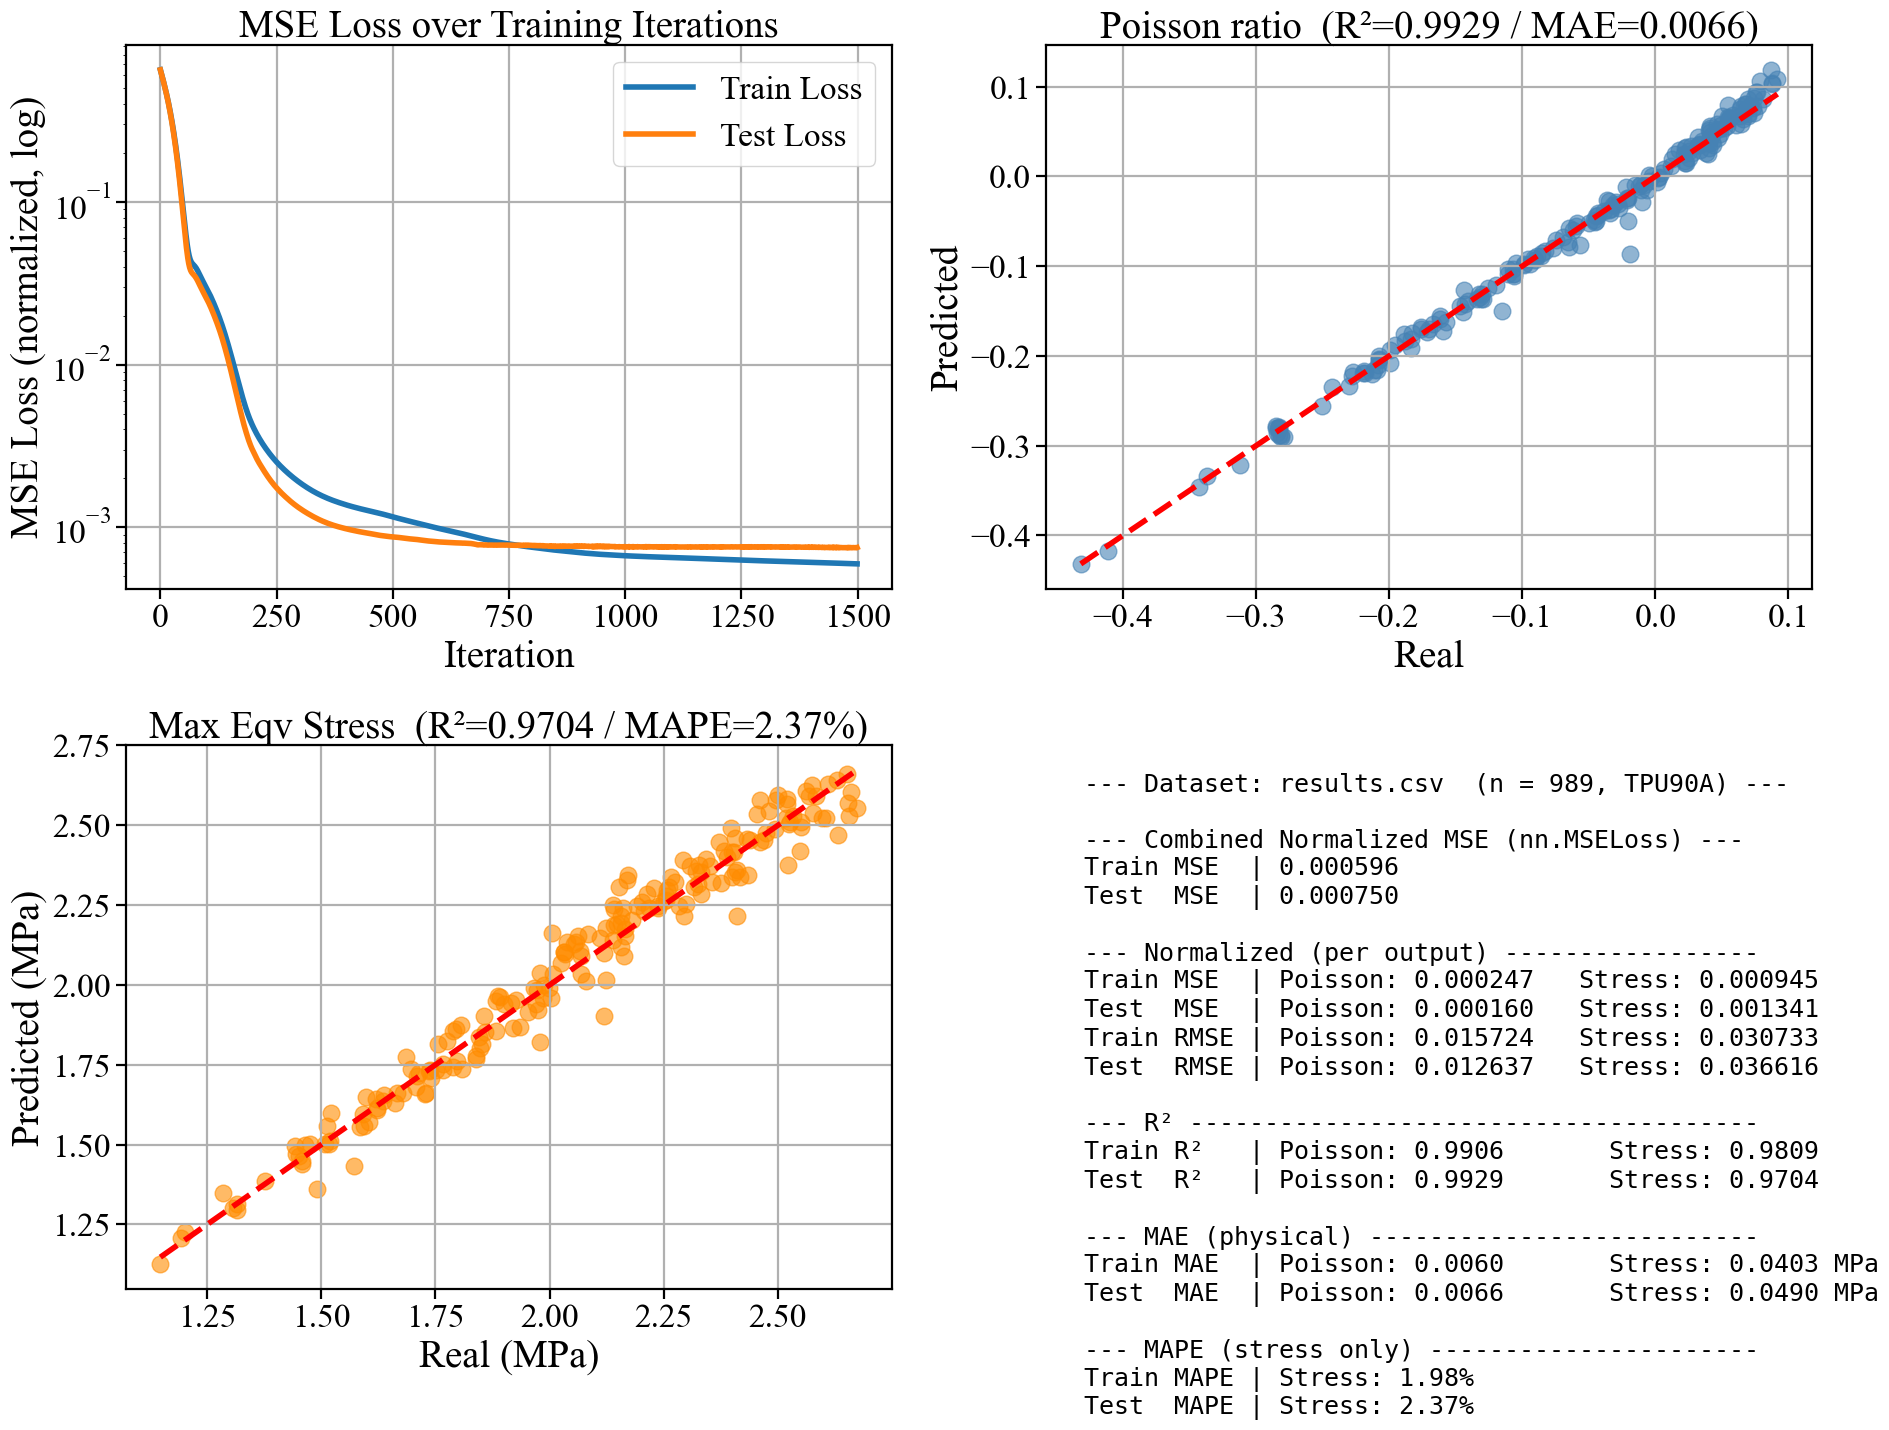

In [11]:
model.eval()
with torch.no_grad():
    y_test_pred  = model(x_test).numpy()
    y_test_real  = y_test.numpy()
    y_train_pred = model(x_train).numpy()
    y_train_real = y_train.numpy()

def denorm(y_norm, y_min, y_max):
    return y_norm * (y_max - y_min) + y_min

y_test_pred_real  = denorm(y_test_pred,  y_min_data, y_max_data)
y_test_real_real  = denorm(y_test_real,  y_min_data, y_max_data)
y_train_pred_real = denorm(y_train_pred, y_min_data, y_max_data)
y_train_real_real = denorm(y_train_real, y_min_data, y_max_data)

r2_test_y1  = r2_score(y_test_real_real[:, 0],  y_test_pred_real[:, 0])
r2_test_y2  = r2_score(y_test_real_real[:, 1],  y_test_pred_real[:, 1])
r2_train_y1 = r2_score(y_train_real_real[:, 0], y_train_pred_real[:, 0])
r2_train_y2 = r2_score(y_train_real_real[:, 1], y_train_pred_real[:, 1])

mse_test_y1 = np.mean((y_test_real_real[:, 0] - y_test_pred_real[:, 0])**2)
mse_test_y2 = np.mean((y_test_real_real[:, 1] - y_test_pred_real[:, 1])**2)

rmse_test_y1 = np.sqrt(mse_test_y1)
rmse_test_y2 = np.sqrt(mse_test_y2)

mse_train_y1  = np.mean((y_train_pred_real[:, 0] - y_train_real_real[:, 0])**2)
mse_train_y2  = np.mean((y_train_pred_real[:, 1] - y_train_real_real[:, 1])**2)
rmse_train_y1 = np.sqrt(mse_train_y1)
rmse_train_y2 = np.sqrt(mse_train_y2)

mse_norm_train_y1  = np.mean((y_train_pred[:, 0] - y_train_real[:, 0])**2)
mse_norm_train_y2  = np.mean((y_train_pred[:, 1] - y_train_real[:, 1])**2)
mse_norm_test_y1   = np.mean((y_test_pred[:, 0]  - y_test_real[:, 0])**2)
mse_norm_test_y2   = np.mean((y_test_pred[:, 1]  - y_test_real[:, 1])**2)
rmse_norm_train_y1 = np.sqrt(mse_norm_train_y1)
rmse_norm_train_y2 = np.sqrt(mse_norm_train_y2)
rmse_norm_test_y1  = np.sqrt(mse_norm_test_y1)
rmse_norm_test_y2  = np.sqrt(mse_norm_test_y2)

mae_train_y1 = np.mean(np.abs(y_train_pred_real[:, 0] - y_train_real_real[:, 0]))
mae_train_y2 = np.mean(np.abs(y_train_pred_real[:, 1] - y_train_real_real[:, 1]))
mae_test_y1  = np.mean(np.abs(y_test_pred_real[:, 0]  - y_test_real_real[:, 0]))
mae_test_y2  = np.mean(np.abs(y_test_pred_real[:, 1]  - y_test_real_real[:, 1]))

y1_range = y_max_data[0] - y_min_data[0]
nmae_train_y1 = mae_train_y1 / y1_range * 100
nmae_test_y1  = mae_test_y1  / y1_range * 100

mape_train_y2 = np.mean(np.abs((y_train_pred_real[:, 1] - y_train_real_real[:, 1])
                                / y_train_real_real[:, 1])) * 100
mape_test_y2  = np.mean(np.abs((y_test_pred_real[:, 1]  - y_test_real_real[:, 1])
                                / y_test_real_real[:, 1])) * 100

W = 78
print('=' * W)
print(f'  {"[Combined Normalized MSE — nn.MSELoss]": ^{W-4}}')
print('-' * W)
print(f'  Final Train MSE (normalized) : {train_loss[-1]:.6f}')
print(f'  Final Test  MSE (normalized) : {test_loss[-1]:.6f}')
print('=' * W)
print(f'  {"[Normalized — per output]":^{W-4}}')
print('-' * W)
print(f'  MSE  (Train) | 포아송비: {mse_norm_train_y1:.6f}       | 최대등가응력: {mse_norm_train_y2:.6f}')
print(f'  MSE  (Test)  | 포아송비: {mse_norm_test_y1:.6f}       | 최대등가응력: {mse_norm_test_y2:.6f}')
print(f'  RMSE (Train) | 포아송비: {rmse_norm_train_y1:.6f}       | 최대등가응력: {rmse_norm_train_y2:.6f}')
print(f'  RMSE (Test)  | 포아송비: {rmse_norm_test_y1:.6f}       | 최대등가응력: {rmse_norm_test_y2:.6f}')
print('=' * W)
print(f'  {"[Denormalized — physical units]":^{W-4}}')
print('-' * W)
print(f'  MSE  (Train) | 포아송비: {mse_train_y1:.6f}       | 최대등가응력: {mse_train_y2:.6f} MPa²')
print(f'  MSE  (Test)  | 포아송비: {mse_test_y1:.6f}       | 최대등가응력: {mse_test_y2:.6f} MPa²')
print(f'  RMSE (Train) | 포아송비: {rmse_train_y1:.6f}       | 최대등가응력: {rmse_train_y2:.6f} MPa')
print(f'  RMSE (Test)  | 포아송비: {rmse_test_y1:.6f}       | 최대등가응력: {rmse_test_y2:.6f} MPa')
print('=' * W)
print(f'  {"[R²]":^{W-4}}')
print('-' * W)
print(f'  R²   (Train) | 포아송비: {r2_train_y1:.6f}       | 최대등가응력: {r2_train_y2:.6f}')
print(f'  R²   (Test)  | 포아송비: {r2_test_y1:.6f}       | 최대등가응력: {r2_test_y2:.6f}')
print('=' * W)
print(f'  {"[MAE / MAPE]":^{W-4}}')
print('-' * W)
print(f'  MAE  (Train) | 포아송비: {mae_train_y1:.6f}       | 최대등가응력: {mae_train_y2:.6f} MPa')
print(f'  MAE  (Test)  | 포아송비: {mae_test_y1:.6f}       | 최대등가응력: {mae_test_y2:.6f} MPa')
print(f'  MAPE (Train) | 포아송비: (0 교차로 생략)     | 최대등가응력: {mape_train_y2:.4f}%')
print(f'  MAPE (Test)  | 포아송비: (0 교차로 생략)     | 최대등가응력: {mape_test_y2:.4f}%')
print(f'  ※ 포아송비 MAE를 전체 범위({y1_range:.4f})로 나눈 비율: '
      f'Train {nmae_train_y1:.2f}% / Test {nmae_test_y1:.2f}%')
print('=' * W)

FONT_SCALE = 2.0   # 글자 배율
LINE_SCALE = 2.0   # 선 굵기 / 마커 크기 배율
plt.rcParams.update({
    'font.family':       'serif',
    'font.serif':        ['Times New Roman', 'Times', 'STIXGeneral', 'DejaVu Serif'],

    # ── 글자 크기 ──
    'font.size':         12 * FONT_SCALE,   # 기본 글자 크기
    'axes.titlesize':    14 * FONT_SCALE,   # 각 그래프 제목
    'axes.labelsize':    14 * FONT_SCALE,   # x축 / y축 이름
    'xtick.labelsize':   12 * FONT_SCALE,   # x축 눈금 숫자
    'ytick.labelsize':   12 * FONT_SCALE,   # y축 눈금 숫자
    'legend.fontsize':   12 * FONT_SCALE,   # 범례

    'lines.linewidth':   2.0 * LINE_SCALE,  # loss 곡선, 대각선 기준선
    'lines.markersize':  6.0 * LINE_SCALE,  # 산점도 점 크기
    'axes.linewidth':    0.8 * LINE_SCALE,  # 그래프 테두리
    'grid.linewidth':    0.8 * LINE_SCALE,  # 격자
    'xtick.major.width': 0.8 * LINE_SCALE,  # 눈금 선 굵기
    'ytick.major.width': 0.8 * LINE_SCALE,
    'xtick.major.size':  3.5 * LINE_SCALE,  # 눈금 선 길이
    'ytick.major.size':  3.5 * LINE_SCALE,
})

fig, axes = plt.subplots(2, 2, figsize=(20, 15))

axes[0, 0].plot(train_loss, label='Train Loss')
axes[0, 0].plot(test_loss,  label='Test Loss')
axes[0, 0].set_yscale('log')
axes[0, 0].set_title('MSE Loss over Training Iterations')
axes[0, 0].set_xlabel('Iteration')
axes[0, 0].set_ylabel('MSE Loss (normalized, log)')
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].scatter(y_test_real_real[:, 0], y_test_pred_real[:, 0], alpha=0.6, color='steelblue')
lim = [y_test_real_real[:, 0].min(), y_test_real_real[:, 0].max()]
axes[0, 1].plot(lim, lim, 'r--')
axes[0, 1].set_title(f'Poisson ratio  (R²={r2_test_y1:.4f} / MAE={mae_test_y1:.4f})')
axes[0, 1].set_xlabel('Real')
axes[0, 1].set_ylabel('Predicted')
axes[0, 1].grid(True)

axes[1, 0].scatter(y_test_real_real[:, 1], y_test_pred_real[:, 1], alpha=0.6, color='darkorange')
lim2 = [y_test_real_real[:, 1].min(), y_test_real_real[:, 1].max()]
axes[1, 0].plot(lim2, lim2, 'r--')
axes[1, 0].set_title(f'Max Eqv Stress  (R²={r2_test_y2:.4f} / MAPE={mape_test_y2:.2f}%)')
axes[1, 0].set_xlabel('Real (MPa)')
axes[1, 0].set_ylabel('Predicted (MPa)')
axes[1, 0].grid(True)

axes[1, 1].axis('off')
summary = (
    f'--- Dataset: {CSV_PATH}  (n = {n}, {TAG}) ---\n'
    f'\n'
    f'--- Combined Normalized MSE (nn.MSELoss) ---\n'
    f'Train MSE  | {train_loss[-1]:.6f}\n'
    f'Test  MSE  | {test_loss[-1]:.6f}\n'
    f'\n'
    f'--- Normalized (per output) -----------------\n'
    f'Train MSE  | Poisson: {mse_norm_train_y1:.6f}   Stress: {mse_norm_train_y2:.6f}\n'
    f'Test  MSE  | Poisson: {mse_norm_test_y1:.6f}   Stress: {mse_norm_test_y2:.6f}\n'
    f'Train RMSE | Poisson: {rmse_norm_train_y1:.6f}   Stress: {rmse_norm_train_y2:.6f}\n'
    f'Test  RMSE | Poisson: {rmse_norm_test_y1:.6f}   Stress: {rmse_norm_test_y2:.6f}\n'
    f'\n'
    f'--- R² --------------------------------------\n'
    f'Train R²   | Poisson: {r2_train_y1:.4f}       Stress: {r2_train_y2:.4f}\n'
    f'Test  R²   | Poisson: {r2_test_y1:.4f}       Stress: {r2_test_y2:.4f}\n'
    f'\n'
    f'--- MAE (physical) --------------------------\n'
    f'Train MAE  | Poisson: {mae_train_y1:.4f}       Stress: {mae_train_y2:.4f} MPa\n'
    f'Test  MAE  | Poisson: {mae_test_y1:.4f}       Stress: {mae_test_y2:.4f} MPa\n'
    f'\n'
    f'--- MAPE (stress only) ----------------------\n'
    f'Train MAPE | Stress: {mape_train_y2:.2f}%\n'
    f'Test  MAPE | Stress: {mape_test_y2:.2f}%'
)
axes[1, 1].text(0.05, 0.95, summary, fontsize=9 * FONT_SCALE, va='top', family='monospace',
                transform=axes[1, 1].transAxes)

plt.tight_layout()
plt.savefig(f'BPNN_{TAG}_result.png', dpi=300)
plt.show()

In [12]:
RUN_NOTE = ''

import os, re, json, shutil, hashlib
from datetime import datetime

try:
    _ = (model, optimizer, scheduler, criterion, n_epochs, train_loss, test_loss,
         r2_test_y2, mape_test_y2, mae_test_y1, CSV_PATH, TAG, MODEL_PATH, SEED)
except NameError as _e:
    raise RuntimeError(f'셀 0~4를 먼저 실행해야 한다 → {_e}')

LOG_MD   = 'Surrogate model results.md'
RUNS_DIR = 'runs'
os.makedirs(RUNS_DIR, exist_ok=True)

_nums   = [int(m.group(1)) for d in os.listdir(RUNS_DIR)
           if (m := re.fullmatch(r'run_(\d+)', d))]
run_no  = max(_nums, default=0) + 1
run_id  = f'run_{run_no:03d}'
run_dir = os.path.join(RUNS_DIR, run_id)
os.makedirs(run_dir, exist_ok=True)
stamp   = datetime.now().strftime('%Y-%m-%d %H:%M')

_lin   = [m for m in model.net if isinstance(m, nn.Linear)]
hidden = [m.out_features for m in _lin[:-1]]
_acts  = [type(m).__name__ for m in model.net if not isinstance(m, nn.Linear)]

hp = {
    '구조':            ' → '.join([str(_lin[0].in_features)] + [str(h) for h in hidden]
                                  + [str(_lin[-1].out_features)]),
    '은닉층':          '-'.join(str(h) for h in hidden),
    '활성화 함수':      ', '.join(dict.fromkeys(_acts)) if _acts else 'none',
    'Optimizer':      type(optimizer).__name__,
    '손실함수':         type(criterion).__name__,
    'lr (초기)':       f"{optimizer.defaults['lr']:.2e}",
    'lr (종료 시점)':   f"{optimizer.param_groups[0]['lr']:.2e}",
    'weight decay':   f"{optimizer.defaults.get('weight_decay', 0.0):.2e}",
    'Epochs':         n_epochs,
    '배치':            'full-batch',
    'Scheduler':      f"{type(scheduler).__name__}"
                      f"(factor={getattr(scheduler, 'factor', '-')}, "
                      f"patience={getattr(scheduler, 'patience', '-')})",
    'Train/Test 분할': f'{train_size} / {n - train_size}'
                      f' ({train_size/n:.0%} / {1 - train_size/n:.0%})',
    'seed':           SEED,
}

with open(CSV_PATH, 'rb') as _f:
    csv_md5 = hashlib.md5(_f.read()).hexdigest()[:12]

ds = {
    'CSV':          CSV_PATH,
    'CSV md5':      csv_md5,
    '전체 행 수':     int(len(df_raw)),
    '유효 데이터':    int(n),
    '포아송비 범위':  f'{y_np[:, 0].min():.4f} ~ {y_np[:, 0].max():.4f}',
    '응력 범위':     f'{y_np[:, 1].min():.4f} ~ {y_np[:, 1].max():.4f} MPa',
}

best_ep   = int(np.argmin(test_loss)) + 1
best_test = float(min(test_loss))

met = {
    'combined': {'train': float(train_loss[-1]), 'test': float(test_loss[-1]),
                 'best_test': best_test, 'best_epoch': best_ep},
    'norm': {'mse_train':  [float(mse_norm_train_y1),  float(mse_norm_train_y2)],
             'mse_test':   [float(mse_norm_test_y1),   float(mse_norm_test_y2)],
             'rmse_train': [float(rmse_norm_train_y1), float(rmse_norm_train_y2)],
             'rmse_test':  [float(rmse_norm_test_y1),  float(rmse_norm_test_y2)]},
    'phys': {'mse_train':  [float(mse_train_y1),  float(mse_train_y2)],
             'mse_test':   [float(mse_test_y1),   float(mse_test_y2)],
             'rmse_train': [float(rmse_train_y1), float(rmse_train_y2)],
             'rmse_test':  [float(rmse_test_y1),  float(rmse_test_y2)]},
    'r2':   {'train': [float(r2_train_y1), float(r2_train_y2)],
             'test':  [float(r2_test_y1),  float(r2_test_y2)]},
    'mae':  {'train': [float(mae_train_y1), float(mae_train_y2)],
             'test':  [float(mae_test_y1),  float(mae_test_y2)]},
    'mape_stress': {'train': float(mape_train_y2), 'test': float(mape_test_y2)},
    'nmae_poisson': {'train': float(nmae_train_y1), 'test': float(nmae_test_y1)},
}

png_src = f'BPNN_{TAG}_result.png'
shutil.copyfile(png_src,    os.path.join(run_dir, 'result.png'))
shutil.copyfile(MODEL_PATH, os.path.join(run_dir, 'model.pth'))
np.savez_compressed(os.path.join(run_dir, 'loss_curves.npz'),
                    train=np.array(train_loss, dtype=np.float32),
                    test=np.array(test_loss,  dtype=np.float32))
with open(os.path.join(run_dir, 'record.json'), 'w', encoding='utf-8') as _f:
    json.dump({'run_id': run_id, 'datetime': stamp, 'note': RUN_NOTE,
               'dataset': ds, 'hyperparameters': hp, 'metrics': met},
              _f, indent=2, ensure_ascii=False)

T_END   = '<!-- SUMMARY_TABLE_END -->'
UPD_TAG = '<!-- LAST_UPDATED -->'

row = (f"| `{run_id}` | {stamp} | {ds['유효 데이터']} | {hp['은닉층']} | {hp['Epochs']} | "
       f"{hp['lr (초기)']} | {hp['weight decay']} | {met['r2']['test'][0]:.4f} | "
       f"**{met['r2']['test'][1]:.4f}** | **{met['mape_stress']['test']:.2f}%** | "
       f"{met['mae']['test'][1]:.4f} | {RUN_NOTE or '-'} |")


def _tbl(title, header, rows):
    out = [f'**{title}**', '', header[0], header[1]]
    out += rows
    out.append('')
    return '\n'.join(out)


detail = f"""
### {run_id} — {stamp}

- **메모**: {RUN_NOTE or '(없음)'}
- **산출물**: [`{run_dir}/result.png`]({run_dir.replace(' ', '%20')}/result.png) ·
  `{run_dir}/model.pth` · `{run_dir}/loss_curves.npz` · `{run_dir}/record.json`

{_tbl('데이터셋', ('| 항목 | 값 |', '|---|---|'),
      [f'| {k} | {v} |' for k, v in ds.items()])}
{_tbl('하이퍼파라미터', ('| 항목 | 값 |', '|---|---|'),
      [f'| {k} | {v} |' for k, v in hp.items()])}
**전체 정규화 MSE (nn.MSELoss)**

| 항목 | 값 |
|---|---:|
| Final Train MSE | {met['combined']['train']:.6f} |
| Final Test MSE | {met['combined']['test']:.6f} |
| Best Test MSE | {met['combined']['best_test']:.6f} (epoch {met['combined']['best_epoch']}) |

**정규화 기준 — 출력별**

| 지표 | 포아송비 | 최대등가응력 |
|---|---:|---:|
| MSE (Train) | {met['norm']['mse_train'][0]:.6f} | {met['norm']['mse_train'][1]:.6f} |
| MSE (Test) | {met['norm']['mse_test'][0]:.6f} | {met['norm']['mse_test'][1]:.6f} |
| RMSE (Train) | {met['norm']['rmse_train'][0]:.6f} | {met['norm']['rmse_train'][1]:.6f} |
| RMSE (Test) | {met['norm']['rmse_test'][0]:.6f} | {met['norm']['rmse_test'][1]:.6f} |

**물리 단위 (역정규화)**

| 지표 | 포아송비 | 최대등가응력 |
|---|---:|---:|
| MSE (Train) | {met['phys']['mse_train'][0]:.6f} | {met['phys']['mse_train'][1]:.6f} MPa² |
| MSE (Test) | {met['phys']['mse_test'][0]:.6f} | {met['phys']['mse_test'][1]:.6f} MPa² |
| RMSE (Train) | {met['phys']['rmse_train'][0]:.6f} | {met['phys']['rmse_train'][1]:.6f} MPa |
| RMSE (Test) | {met['phys']['rmse_test'][0]:.6f} | {met['phys']['rmse_test'][1]:.6f} MPa |

**R² / MAE / MAPE**

| 지표 | 포아송비 | 최대등가응력 |
|---|---:|---:|
| R² (Train) | {met['r2']['train'][0]:.6f} | {met['r2']['train'][1]:.6f} |
| R² (Test) | {met['r2']['test'][0]:.6f} | **{met['r2']['test'][1]:.6f}** |
| MAE (Train) | {met['mae']['train'][0]:.6f} | {met['mae']['train'][1]:.6f} MPa |
| MAE (Test) | {met['mae']['test'][0]:.6f} | {met['mae']['test'][1]:.6f} MPa |
| MAPE (Train) | (0 교차로 생략) | {met['mape_stress']['train']:.4f}% |
| MAPE (Test) | (0 교차로 생략) | **{met['mape_stress']['test']:.4f}%** |

포아송비 MAE를 전체 범위로 나눈 비율 — Train {met['nmae_poisson']['train']:.2f}% / Test {met['nmae_poisson']['test']:.2f}%

![{run_id}]({run_dir.replace(' ', '%20')}/result.png)

---
"""

with open(LOG_MD, encoding='utf-8') as _f:
    md = _f.read()

assert T_END in md, f'{LOG_MD}에 {T_END} 표식이 없다'
md = md.replace(T_END, row + '\n' + T_END)                      # 요약표 끝에 행 추가
md = re.sub(rf'({re.escape(UPD_TAG)}\n).*', rf'\g<1>> **최종 기록: {stamp} (KST) — {run_id}**',
            md, count=1)                                        # 최종 기록 시각 갱신
md = md.rstrip('\n') + '\n' + detail                            # 문서 끝에 상세 추가

with open(LOG_MD, 'w', encoding='utf-8') as _f:
    _f.write(md)

print(f'기록 완료: {LOG_MD}  ←  {run_id} ({stamp})')
print(f'산출물 사본: {run_dir}/  (result.png, model.pth, loss_curves.npz, record.json)')
print(f"  σ R²(Test) = {met['r2']['test'][1]:.6f} | "
      f"σ MAPE(Test) = {met['mape_stress']['test']:.4f}% | "
      f"σ MAE(Test) = {met['mae']['test'][1]:.4f} MPa")

기록 완료: Surrogate model results.md  ←  run_005 (2026-09-23 03:31)
산출물 사본: runs/run_005/  (result.png, model.pth, loss_curves.npz, record.json)
  σ R²(Test) = 0.970391 | σ MAPE(Test) = 2.3697% | σ MAE(Test) = 0.0490 MPa
